# 07 · Test: Pune 2018 (run once)

The only notebook that turns the Pune data into episodes and runs controllers on them. It refuses a second run: after the first run
(`results/test_done.json`) it only re-reads the frozen, hash-checked results. Every controller is frozen (`results/freeze.json`).
Questions and pass rules: `results/FINAL_SPEC.md` §7.

In [1]:
import sys, os, json, hashlib, pickle, time, datetime, warnings
from dataclasses import replace
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src")); os.environ["PYTHONPATH"] = str(ROOT / "src")
PROC, RES, MOD, A = ROOT / "data" / "processed", ROOT / "results", ROOT / "models", ROOT / "_archive"
sha = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()
assert sha(RES / "FINAL_SPEC.md") == json.loads((RES / "FINAL_SPEC_lock.json").read_text())["sha256"], "plan changed"
FZ = json.loads((RES / "freeze.json").read_text())
assert sha(MOD / "forecasters.pkl") == FZ["forecasters_sha256"]
for k, v in FZ["checkpoints"].items(): assert sha(MOD / "rl" / k / "best_model.zip") == v["sha256"], f"{k} changed after the freeze"
for k, v in FZ["reference_ppo_bc_v3"].items(): assert sha(ROOT / k) == v, f"{k} changed"
split = json.loads((PROC / "split.json").read_text())
assert hashlib.sha256(json.dumps(split, indent=1).encode()).hexdigest() == json.loads((PROC / "split_lock.json").read_text())["sha256"]
from sim import load_cfg, load_bank, evaluate
from learn import NETS, env_kw
CFG = load_cfg(ROOT); FINAL = FZ["final_net"]; EPS_STAR = FZ["mpc_cc"]["eps_star"]
DONE = (RES / "test_done.json").exists()
print(f"all locks and freezes verified | final controller {FINAL} | MPC-CC eps* {EPS_STAR} | test already run: {DONE}")

all locks and freezes verified | final controller GRU | MPC-CC eps* 0.1 | test already run: False


## 1. Pune episodes (forecasts from the frozen forecasters; the earlier PPO-BC gets its own frozen forecasters)

In [2]:
from features import forecasts, make_bank_region
BANK_PATH = PROC / "bank_test.pkl"
if not BANK_PATH.exists():
    tab = {k: pd.read_parquet(PROC / f"Pune_{k}.parquet") for k in ["cut", "demand", "supplied_load"]}
    tab["solar"] = pd.read_parquet(PROC / "Pune_solar_15min.parquet"); tab["hourly"] = pd.read_parquet(PROC / "Pune_solar_hourly_causal.parquet")
    F = pickle.loads((MOD / "forecasters.pkl").read_bytes()); assert F["gate"]["cut"] and F["gate"]["load"], "a failed gate needs the baseline replacement"
    cp, lf = forecasts(tab, F, split["scalers"])
    Fref = pickle.loads((MOD / "reference" / "forecasters_v2.pkl").read_bytes())
    sc_ref = json.loads((A / "data_processed" / "split.json").read_text())["scalers"]          # the scalers PPO-BC (v3) was trained with
    cpr, lfr = forecasts(tab, Fref, sc_ref)
    BANK_PATH.write_bytes(pickle.dumps({"Pune": make_bank_region(tab, cp, lf, {"cut_p_ref": cpr, "load_fc_ref": lfr})}))
BANK = load_bank(BANK_PATH); B = BANK["Pune"]
TEST = []
for w in split["test"]:
    t0 = int((np.datetime64(pd.Timestamp(w["start"]), "m") - B["start"]) / np.timedelta64(15, "m"))
    TEST.append({"region": "Pune", "start": w["start"], "t0": t0, "pool_idx": sorted(B["homes"].index(h) for h in w["pool"]),
                 "homes_idx": sorted(B["homes"].index(h) for h in w["homes"])})
cuth = np.mean([B["cut"][e["t0"]:e["t0"] + 672][:, e["homes_idx"]].mean() * 24 for e in TEST])
print(f"Pune test: {len(TEST)} weeks ({TEST[0]['start'][:10]} to {TEST[-1]['start'][:10]}) | cut hours per home-day {cuth:.2f}")

Pune test: 50 weeks (2018-01-15 to 2018-12-24) | cut hours per home-day 1.07


## 2. Run every frozen method once (each finished block is cached; raw rows are not inspected until all are done)

In [3]:
PART = RES / "_test_cache"; PART.mkdir(exist_ok=True)
def cached(key, fn):
    f = PART / f"{key}.pkl"
    if f.exists(): return pickle.loads(f.read_bytes())
    r = fn(); f.write_bytes(pickle.dumps(r)); print(f"  {key} saved", flush=True); return r
def job(kind, ids, bank_path, cfg, eps, arg=None):
    import sys, os; sys.path.insert(0, os.environ["PYTHONPATH"])
    from dataclasses import replace
    from sim import load_bank
    from controllers import run_policy, run_perfect, run_mpc
    bank = load_bank(bank_path); out = []
    for i in ids:
        if kind == "none": r = run_policy(bank, eps, replace(cfg, pv_kwp_per_home=0.0, batt_kwh_per_home=0.0, batt_kw_per_home=0.0), "idle_full", i)
        elif kind == "solar": r = run_policy(bank, eps, replace(cfg, batt_kwh_per_home=0.0, batt_kw_per_home=0.0), "idle_full", i)
        elif kind == "backup": r = run_policy(bank, eps, cfg, "backup_only", i)
        elif kind == "rule": r = run_policy(bank, eps, cfg, "rule", i)
        elif kind == "rule_shield": r = run_policy(bank, eps, cfg, "rule", i, shield=True)
        elif kind == "pf": r = run_perfect(bank, eps, cfg, i, time_limit=600)
        elif kind == "mpc_v2": r = run_mpc(bank, eps, cfg, i, "v2")
        else: r = run_mpc(bank, eps, cfg, i, "cc", eps_cc=arg)
        out.append(r)
    return out
from stable_baselines3 import PPO
NAMES = {"none": "0 No system", "solar": "1 Solar only", "backup": "2 Backup-only inverter", "rule": "3 Rule-based",
         "rule_shield": "3s Rule-based + shield", "mpc_v2": "4a MPC v2 (risk-aware)", "mpc_cc": "4b MPC-CC", "pf": "5 Perfect foresight"}
if DONE:
    done = json.loads((RES / "test_done.json").read_text())
    assert sha(RES / "test_per_episode.csv") == done["per_episode_sha256"], "frozen test results changed"
    PE = pd.read_csv(RES / "test_per_episode.csv"); print("Test already run on", done["created"], "- re-reading the frozen results")
else:
    t0 = time.time(); rows = []; chunks = [list(range(i, len(TEST), 16)) for i in range(16)]
    for kind in NAMES:
        arg = EPS_STAR if kind == "mpc_cc" else None
        out = cached(kind, lambda: [r for p in Parallel(n_jobs=8)(delayed(job)(kind, c, str(BANK_PATH), CFG, TEST, arg) for c in chunks) for r in p])
        rows += [{"method": NAMES[kind], "seed": np.nan, **r} for r in out]
    for s in range(5):
        m = PPO.load(MOD / "reference" / "ppo_bc_v3" / f"PPO-BC_s{s}.zip", device="cpu")
        out = cached(f"ppo_bc_v3_s{s}", lambda: evaluate(m, BANK, TEST, CFG, dict(shield=True, stack=1, cut_key="cut_p_ref", load_key="load_fc_ref")))
        rows += [{"method": "6 PPO-BC (v3, Mathura only)", "seed": s, **r} for r in out]
    for n in NETS:
        for s in range(5):
            m = PPO.load(MOD / "rl" / f"{n}_s{s}" / "best_model.zip", device="cpu")
            out = cached(f"{n}_s{s}", lambda: evaluate(m, BANK, TEST, CFG, env_kw(n)))
            rows += [{"method": f"7 Nirantar PPO-DAgger ({n})", "seed": s, **r} for r in out]
    PE = pd.DataFrame(rows); PE.to_csv(RES / "test_per_episode.csv", index=False)
    (RES / "test_done.json").write_text(json.dumps({"created": datetime.datetime.now().isoformat(timespec="seconds"),
                                                    "per_episode_sha256": sha(RES / "test_per_episode.csv"), "spec_sha256": FZ["spec_sha256"]}, indent=1))
    print(f"Test run once and frozen ({(time.time() - t0) / 60:.0f} min)")

  none saved


  solar saved


  backup saved


  rule saved


  rule_shield saved


  mpc_v2 saved


... (14 outputs left out)

  GRU_s2 saved


  GRU_s3 saved


  GRU_s4 saved


Test run once and frozen (21 min)


## 3. Every outcome, every method (learned methods: mean over seeds 0–4)

In [4]:
FINAL_NAME = f"7 Nirantar PPO-DAgger ({FINAL})"
COLS = {"LOLH_ess_h_per_home_month": "Essentials off (h/home·month)", "cut_demand_served_pct": "Cut demand served (%)",
        "evening_import_kwh_per_day": "Evening grid (kWh/day)", "evening_excess_kwh_per_day": "Above cap (kWh/day)",
        "battery_cycles_per_day": "Battery cycles/day", "wear_cost_inr_per_home_month": "Wear (₹/home·month)",
        "jain_fairness": "Fairness (Jain)", "shield_rate_pct": "Shield changed (% steps)", "reward_per_week": "Reward/week"}
W = PE.groupby(["method", "episode"])[list(COLS)].mean()                  # seed mean per week
tab = W.groupby("method").mean().rename(columns=COLS)
r_none, r_pf, r_rule = tab.loc["0 No system", "Reward/week"], tab.loc["5 Perfect foresight", "Reward/week"], tab.loc["3 Rule-based", "Reward/week"]
tab["Score: no system 0 → perfect 100"] = 100 * (tab["Reward/week"] - r_none) / (r_pf - r_none)
tab["Gap closed rule → perfect (%)"] = 100 * (tab["Reward/week"] - r_rule) / (r_pf - r_rule)
tab = tab.sort_values("Reward/week", ascending=False); tab.round(3).to_csv(RES / "test_results.csv", encoding="utf-8"); display(tab.round(2))
pf = PE[PE.method == "5 Perfect foresight"]; print(f"perfect foresight: {int(pf.pf_time_limited.sum())} of {len(pf)} weeks capped at 600 s, largest gap {pf.pf_mip_gap.max():.4f}")

,Essentials off (h/home·month),Cut demand served (%),Evening grid (kWh/day),Above cap (kWh/day),Battery cycles/day,Wear (₹/home·month),Fairness (Jain),Shield changed (% steps),Reward/week,Score: no system 0 → perfect 100,Gap closed rule → perfect (%)
method,,,,,,,,,,,
5 Perfect foresight,0.19,98.46,3.27,0.00,0.90,24.02,1.00,0.00,-3.36,100.00,100.00
7 Nirantar PPO-DAgger (MLP),1.05,93.49,3.55,0.01,0.86,22.70,0.99,1.32,-3.95,94.55,63.07
7 Nirantar PPO-DAgger (GRU),1.05,93.52,3.62,0.00,0.90,23.98,0.99,2.62,-4.04,93.73,57.58
"6 PPO-BC (v3, Mathura only)",1.43,90.53,3.49,0.01,0.85,22.64,0.98,2.29,-4.14,92.81,51.30
4b MPC-CC,3.25,82.41,3.75,0.01,0.79,21.08,0.95,0.00,-4.91,85.75,3.53
3s Rule-based + shield,0.78,93.28,5.20,0.01,0.63,16.62,0.99,0.04,-4.96,85.29,0.43
3 Rule-based,0.89,93.31,5.20,0.01,0.63,16.63,0.99,0.00,-4.97,85.23,0.00
4a MPC v2 (risk-aware),3.04,79.96,3.73,0.01,0.80,21.19,0.95,2.91,-5.00,84.92,-2.12
2 Backup-only inverter,0.43,98.04,9.60,0.05,0.10,2.57,1.00,0.00,-7.15,65.26,-135.21


perfect foresight: 0 of 50 weeks capped at 600 s, largest gap 0.0001


## 4. Main questions (paired per week, 95% bootstrap CI, 10,000 resamples, seed 0)

In [5]:
def boot(d, n=10000, seed=0):
    d = np.asarray(d); rng = np.random.default_rng(seed); m = d[rng.integers(0, len(d), (n, len(d)))].mean(1)
    return float(d.mean()), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))
MET = {"reward_per_week": "Reward", "LOLH_ess_h_per_home_month": "Essentials off", "evening_import_kwh_per_day": "Evening grid",
       "cut_demand_served_pct": "Cut demand served"}
def compare(a, b):
    row = {}
    for k, lab in MET.items():
        m, lo, hi = boot(W.loc[a, k].values - W.loc[b, k].values)
        row[f"{lab}: mean"] = round(m, 3); row[f"{lab}: 95% CI"] = f"[{lo:.3f}, {hi:.3f}]"; row[f"_{k}"] = (lo, hi)
    return row
QS = [("Q1", FINAL_NAME, "3 Rule-based"), ("Q2", FINAL_NAME, "4b MPC-CC"), ("Q3", FINAL_NAME, "6 PPO-BC (v3, Mathura only)"),
      ("GRU − MLP", "7 Nirantar PPO-DAgger (GRU)", "7 Nirantar PPO-DAgger (MLP)")]
rows = {q: compare(a, b) for q, a, b in QS}
Q = pd.DataFrame({q: {k: v for k, v in r.items() if not k.startswith("_")} for q, r in rows.items()}).T
Q.insert(0, "comparison", [f"{a.split(' ', 1)[1]} − {b.split(' ', 1)[1]}" for _, a, b in QS])
Q.to_csv(RES / "test_questions.csv", encoding="utf-8"); display(Q)
verdict = {"Q1 final beats rule-based on reward AND essentials-off not worse by 0.5 h": rows["Q1"]["_reward_per_week"][0] > 0 and rows["Q1"]["_LOLH_ess_h_per_home_month"][1] < 0.5,
           "Q2 final beats MPC-CC on reward": rows["Q2"]["_reward_per_week"][0] > 0,
           "Q3 final beats PPO-BC (v3) on reward": rows["Q3"]["_reward_per_week"][0] > 0}
(RES / "test_verdict.json").write_text(json.dumps(verdict, indent=1)); print(json.dumps(verdict, indent=1))

,comparison,Reward: mean,Reward: 95% CI,Essentials off: mean,Essentials off: 95% CI,Evening grid: mean,Evening grid: 95% CI,Cut demand served: mean,Cut demand served: 95% CI
Q1,Nirantar PPO-DAgger (GRU) − Rule-based,0.928,"[0.742, 1.193]",0.165,"[-0.285, 0.495]",-1.583,"[-1.718, -1.474]",0.215,"[-1.176, 1.785]"
Q2,Nirantar PPO-DAgger (GRU) − MPC-CC,0.871,"[0.535, 1.257]",-2.194,"[-3.305, -1.246]",-0.131,"[-0.304, 0.026]",11.115,"[7.694, 14.758]"
Q3,"Nirantar PPO-DAgger (GRU) − PPO-BC (v3, Mathur...",0.101,"[-0.009, 0.224]",-0.38,"[-0.773, -0.065]",0.127,"[0.103, 0.149]",2.997,"[1.847, 4.234]"
GRU − MLP,Nirantar PPO-DAgger (GRU) − Nirantar PPO-DAgge...,-0.089,"[-0.146, -0.031]",0.005,"[-0.213, 0.282]",0.062,"[0.042, 0.082]",0.029,"[-0.459, 0.562]"


{
 "Q1 final beats rule-based on reward AND essentials-off not worse by 0.5 h": true,
 "Q2 final beats MPC-CC on reward": true,
 "Q3 final beats PPO-BC (v3) on reward": false
}


## 5. Per seed (does every seed beat the rule-based controller?) and figures

Essentials off (h/home·month)  \
method                      seed                                  
6 PPO-BC (v3, Mathura only) 0.0                            1.60   
                            1.0                            1.63   
                            2.0                            1.15   
                            3.0                            1.67   
                            4.0                            1.12   
7 Nirantar PPO-DAgger (GRU) 0.0                            1.33   
                            1.0                            1.14   
                            2.0                            0.88   
                            3.0                            0.90   
                            4.0                            1.03   
7 Nirantar PPO-DAgger (MLP) 0.0                            1.15   
                            1.0                            0.84   
                            2.0                            0.93   
                            3.0                            1.41   
                            4.0                            0.92   

                                  Cut demand served (%)  \
method                      seed                          
6 PPO-BC (v3, Mathura only) 0.0                   88.71   
                            1.0                   91.96   
                            2.0                   91.34   
                            3.0                   87.46   
                            4.0                   93.16   
7 Nirantar PPO-DAgger (GRU) 0.0                   92.85   
                            1.0                   94.10   
                            2.0                   93.72   
                            3.0                   93.58   
                            4.0                   93.37   
7 Nirantar PPO-DAgger (MLP) 0.0                   94.26   
                            1.0                   94.40   
                            2.0                   92.76   
                            3.0                   92.48   
                            4.0                   93.58   

                                  Evening grid (kWh/day)  Above cap (kWh/day)  \
method                      seed                                                
6 PPO-BC (v3, Mathura only) 0.0                     3.46                 0.01   
                            1.0                     3.43                 0.01   
                            2.0                     3.48                 0.01   
                            3.0                     3.49                 0.01   
                            4.0                     3.59                 0.00   
7 Nirantar PPO-DAgger (GRU) 0.0                     3.47                 0.00   
                            1.0                     4.03                 0.00   
                            2.0                     3.46                 0.01   
                            3.0                     3.43                 0.00   
                            4.0                     3.70                 0.01   
7 Nirantar PPO-DAgger (MLP) 0.0                     3.65                 0.01   
                            1.0                     3.53                 0.01   
                            2.0                     3.56                 0.01   
                            3.0                     3.46                 0.01   
                            4.0                     3.57                 0.00   

                                  Battery cycles/day  Wear (₹/home·month)  \
method                      seed                                            
6 PPO-BC (v3, Mathura only) 0.0                 0.85                22.61   
                            1.0                 0.86                22.96   
                            2.0                 0.85                22.64   
                            3.0                 0.84                22.40   
                            4.0                 0.

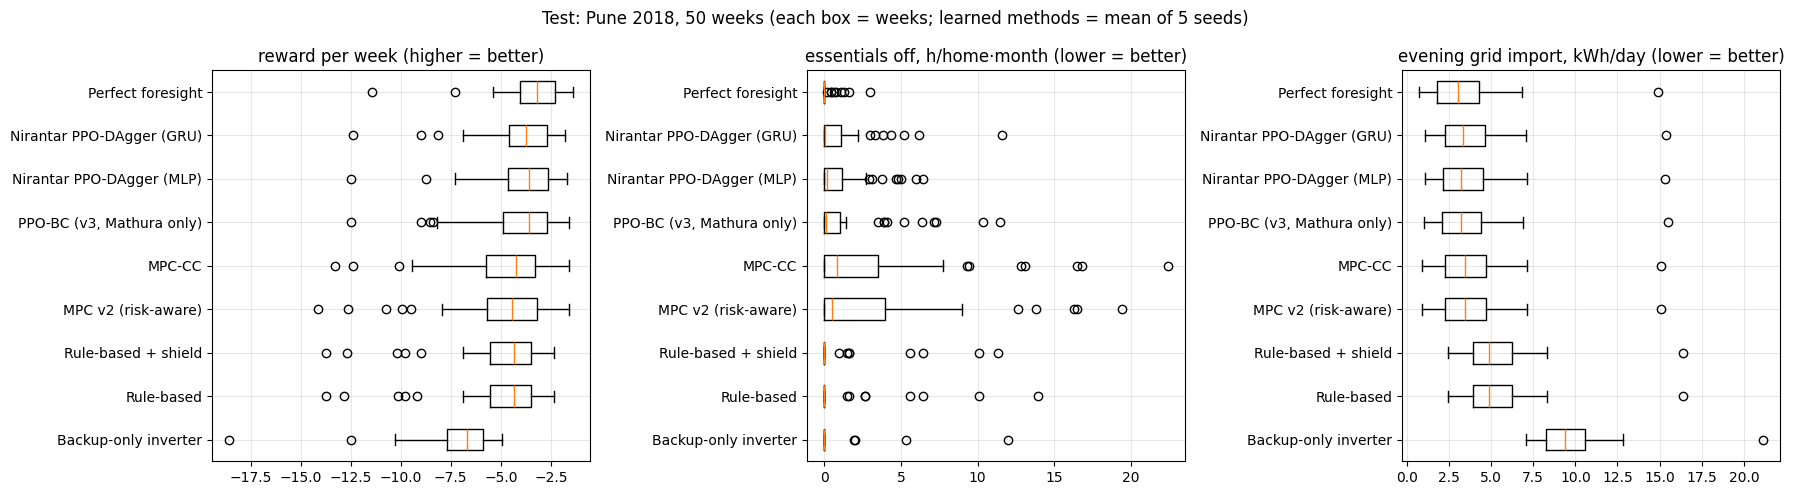

In [6]:
rule_w = W.loc["3 Rule-based", "reward_per_week"]
ps = PE[PE.seed.notna()].groupby(["method", "seed"])[list(COLS)].mean().rename(columns=COLS)
ps["beats rule (reward)"] = [PE[(PE.method == m) & (PE.seed == s)].set_index("episode").reward_per_week.mean() > rule_w.mean() for m, s in ps.index]
ps.round(3).to_csv(RES / "test_per_seed.csv", encoding="utf-8"); display(ps.round(2))
show = ["5 Perfect foresight", FINAL_NAME, "7 Nirantar PPO-DAgger (" + ("MLP" if FINAL == "GRU" else "GRU") + ")", "6 PPO-BC (v3, Mathura only)",
        "4b MPC-CC", "4a MPC v2 (risk-aware)", "3s Rule-based + shield", "3 Rule-based", "2 Backup-only inverter"]
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, k, t in zip(ax, ["reward_per_week", "LOLH_ess_h_per_home_month", "evening_import_kwh_per_day"],
                   ["reward per week (higher = better)", "essentials off, h/home·month (lower = better)", "evening grid import, kWh/day (lower = better)"]):
    a.boxplot([W.loc[m, k].values for m in show][::-1], vert=False, labels=[m.split(" ", 1)[1] for m in show][::-1]); a.set_title(t); a.grid(alpha=.3)
plt.suptitle(f"Test: Pune 2018, {len(TEST)} weeks (each box = weeks; learned methods = mean of 5 seeds)")
plt.tight_layout(); plt.savefig(RES / "figures" / "07_test_pune.png", dpi=130); plt.show()